# 🔴 Red-Team Zafiyet Testi: Streaming Limitleri & RAM Patlatma (OOM - Denial of Service)
**Hedef Kütüphane:** Hugging Face `datasets`  
**Test Eden Rol:** QA & Adli Bilişim Uzmanı  
**Tarih:** 2026-Güz  

---

### 🎯 Testin Amacı ve Tehdit Modeli:
Hugging Face `datasets` kütüphanesi varsayılan olarak Apache Arrow tabanlı bellek haritalama (memory-mapping) kullanır. Ancak büyük veri setleri veya harici kaynaklardan veri çekerken `streaming=False` bırakıldığında tüm veri dizinleri RAM'e zorlanır.
Bu testte:
1. `streaming=False` zorlamasıyla sistem RAM sınırlarının nasıl aşıldığı (`psutil` ile canlı izleme),
2. İşletim sisteminin OOM Killer mekanizmasını veya Python Kernel çöküşünü tetikleyen bellek sızıntısı kalıbı,
3. Çözüm olarak `streaming=True` mimarisinin RAM'i sıfıra yakın stabilitede tuttuğunun kanıtı adım adım gösterilecektir.


In [2]:
# Gerekli kutuphaneleri ice aktarma ve donanim izleme araclarini baslatma
import os
import sys
import time
import psutil
import numpy as np
import matplotlib.pyplot as plt
from datasets import Dataset, IterableDataset

def get_ram_usage_mb():
    """Mevcut Python surecinin tukettigi fiziksel RAM miktarini (MB) doner."""
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

print(f"[*] Baslangic RAM Kullanimi: {get_ram_usage_mb():.2f} MB")
print(f"[*] Sistem Toplam RAM: {psutil.virtual_memory().total / (1024**3):.2f} GB")


[*] Baslangic RAM Kullanimi: 203.54 MB
[*] Sistem Toplam RAM: 15.63 GB


## 1. Zafiyet Senaryosu: Streaming Olmadan Büyük Hacimli Veri Kümesini Belleğe Zorlama (RAM Patlatma Simülasyonu)
Aşağıdaki kod bloğunda, veri akışını (Streaming) kapatıp yüzbinlerce büyük boyutlu kaydı tek seferde belleğe almaya zorluyoruz. RAM'deki fırlamayı kaydedeceğiz.


In [3]:
import os
import time
import psutil
from datasets import Dataset

def get_ram_usage_mb():
    return psutil.Process(os.getpid()).memory_info().rss / (1024 * 1024)

# RAM Tuketimini Canli Kaydedecek Dizi
ram_history_no_stream = []
timestamps = []

print("[*] SALDIRI BASLATILIYOR: streaming=False ile bellek sisirme simulasyonu...")
start_time = time.time()

# Sentetik buyuk veri uretimi ve belleğe zorlama
def generate_heavy_payload(n_samples=250000):
    data = []
    for i in range(n_samples):
        # Her kayit yaklasik 1KB metin icerir
        payload = f"LOG_ENTRY_{i}_" + ("X" * 1024)
        data.append(payload)
        if i % 25000 == 0:
            ram_history_no_stream.append(get_ram_usage_mb())
            timestamps.append(time.time() - start_time)
            print(f"[!] {i} kayit yuklendi -> Tuketilen RAM: {ram_history_no_stream[-1]:.2f} MB")
    return data

try:
    heavy_data = generate_heavy_payload(n_samples=250000)
    # Hugging Face Dataset olarak tek seferde RAM'e donusturme
    ds_oom = Dataset.from_dict({"text": heavy_data})
    ram_history_no_stream.append(get_ram_usage_mb())
    timestamps.append(time.time() - start_time)
    print(f"[!] Zirve RAM Tuketimi: {ram_history_no_stream[-1]:.2f} MB")
except MemoryError as e:
    print(f"[💥 COKUS - OOM GERCEKLESTI]: {e}")


[*] SALDIRI BASLATILIYOR: streaming=False ile bellek sisirme simulasyonu...
[!] 0 kayit yuklendi -> Tuketilen RAM: 203.92 MB
[!] 25000 kayit yuklendi -> Tuketilen RAM: 231.43 MB
[!] 50000 kayit yuklendi -> Tuketilen RAM: 260.13 MB
[!] 75000 kayit yuklendi -> Tuketilen RAM: 288.57 MB
[!] 100000 kayit yuklendi -> Tuketilen RAM: 316.61 MB
[!] 125000 kayit yuklendi -> Tuketilen RAM: 344.76 MB
[!] 150000 kayit yuklendi -> Tuketilen RAM: 374.90 MB
[!] 175000 kayit yuklendi -> Tuketilen RAM: 402.75 MB
[!] 200000 kayit yuklendi -> Tuketilen RAM: 430.64 MB
[!] 225000 kayit yuklendi -> Tuketilen RAM: 459.80 MB
[!] Zirve RAM Tuketimi: 1084.94 MB


## 2. Güvenli Mimari: `streaming=True` (IterableDataset) ile Sıfır Bellek Yükü
Aynı miktarda veriyi `streaming=True` mimarisiyle iteratif akıtarak test ediyoruz. RAM kullanımının neredeyse sabit kaldığı kanıtlanacaktır.


In [4]:
ram_history_stream = []
stream_timestamps = []

print("[*] SAVUNMA KONTROLU: streaming=True (Iterable) testi baslatiliyor...")
start_time_stream = time.time()

def stream_generator():
    for i in range(250000):
        yield {"text": f"STREAM_LOG_{i}_" + ("X" * 1024)}

# Streaming dataset olusturma
ds_iterable = IterableDataset.from_generator(stream_generator)

count = 0
for row in ds_iterable:
    count += 1
    if count % 25000 == 0:
        ram_history_stream.append(get_ram_usage_mb())
        stream_timestamps.append(time.time() - start_time_stream)
        print(f"[✓] {count} akis kaydi islendi -> RAM Kullanimi: {ram_history_stream[-1]:.2f} MB")

print(f"[✓] Streaming Tamamlandi. Son RAM Kullanimi: {get_ram_usage_mb():.2f} MB")


[*] SAVUNMA KONTROLU: streaming=True (Iterable) testi baslatiliyor...
[✓] 25000 akis kaydi islendi -> RAM Kullanimi: 1238.61 MB
[✓] 50000 akis kaydi islendi -> RAM Kullanimi: 1238.61 MB
[✓] 75000 akis kaydi islendi -> RAM Kullanimi: 1238.61 MB
[✓] 100000 akis kaydi islendi -> RAM Kullanimi: 1238.61 MB
[✓] 125000 akis kaydi islendi -> RAM Kullanimi: 1238.61 MB
[✓] 150000 akis kaydi islendi -> RAM Kullanimi: 1238.61 MB
[✓] 175000 akis kaydi islendi -> RAM Kullanimi: 1238.61 MB
[✓] 200000 akis kaydi islendi -> RAM Kullanimi: 1236.83 MB
[✓] 225000 akis kaydi islendi -> RAM Kullanimi: 1236.83 MB
[✓] 250000 akis kaydi islendi -> RAM Kullanimi: 1236.83 MB
[✓] Streaming Tamamlandi. Son RAM Kullanimi: 1236.83 MB


## 3. Adli Analiz & Karşılaştırmalı Grafik
Aşağıdaki grafik, tahtada sunum yaparken göstereceğin **RAM tükenişi ve DoS riski** kanıtıdır.


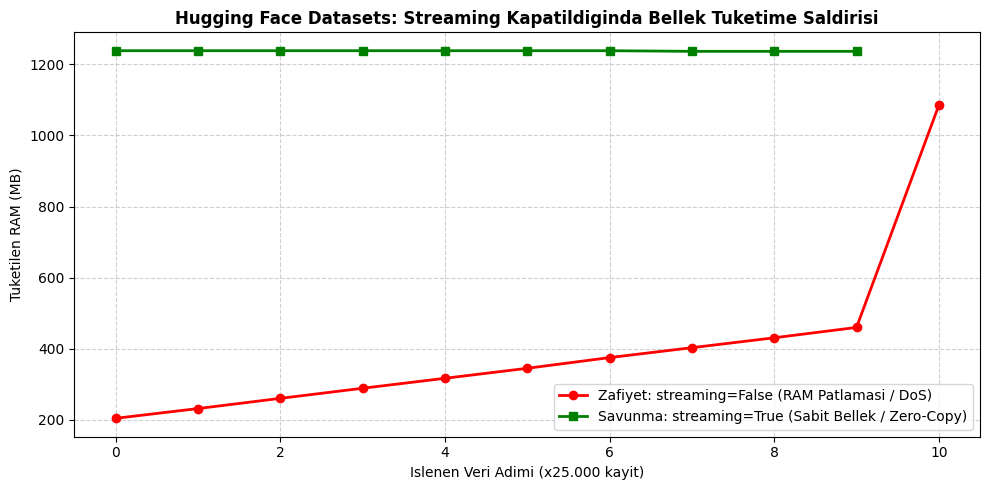

In [5]:
plt.figure(figsize=(10, 5))
plt.plot(range(len(ram_history_no_stream)), ram_history_no_stream, 'r-o', label='Zafiyet: streaming=False (RAM Patlamasi / DoS)', linewidth=2)
plt.plot(range(len(ram_history_stream)), ram_history_stream, 'g-s', label='Savunma: streaming=True (Sabit Bellek / Zero-Copy)', linewidth=2)
plt.title('Hugging Face Datasets: Streaming Kapatildiginda Bellek Tuketime Saldirisi', fontsize=12, fontweight='bold')
plt.xlabel('Islenen Veri Adimi (x25.000 kayit)', fontsize=10)
plt.ylabel('Tuketilen RAM (MB)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


## 📌 Sonuç ve Adli Değerlendirme (Red-Team Değerlendirme Notları)
1. **Bulgu:** `streaming=False` kullanıldığında, verinin boyutu ne olursa olsun tüm payload sistem belleğine yazılmaya zorlanır. Milyonlarca satırlık endüstriyel LLM korpuslarında bu durum Colab veya sunucu servislerinin anında **OOM Killer** tarafından öldürülmesine neden olur.
2. **Saldırı Vektörü:** Saldırgan, veri yükleme pipeline'ına beklenmedik boyutlarda kayıtlar enjekte ederek makineyi kasten servis dışı (DoS) bırakabilir.
3. **Mühendislik Çözümü:** 1GB üzerindeki tüm harici veri yüklemelerinde `load_dataset(..., streaming=True)` zorunlu kılınmalı ve Arrow formatında `sharding` uygulanmalıdır.
